<a href="https://colab.research.google.com/github/Devaji-Rashmika/Deep_Learning/blob/main/skill5(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset directories created successfully!
Generated images: 12
Generated annotations: 60

COCO annotation JSON created successfully!

========== DATASET INFORMATION ==========
Total Images: 12
Total Annotations: 60
Total Categories: 6

Category Names:
1 - car
2 - bus
3 - motorcycle
4 - person
5 - bicycle
6 - traffic_light

========== CLASS DISTRIBUTION ==========


,Category,Count
0,car,12
1,bus,12
2,motorcycle,12
3,person,12
4,bicycle,12
5,traffic_light,0


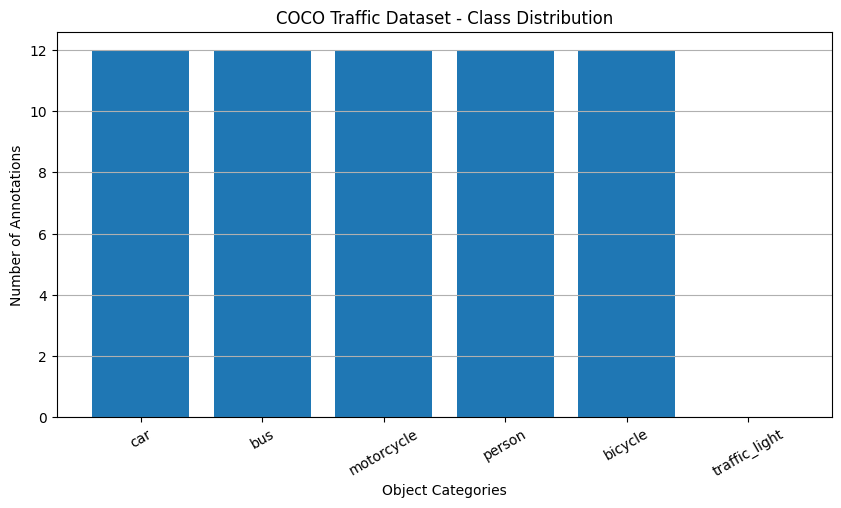

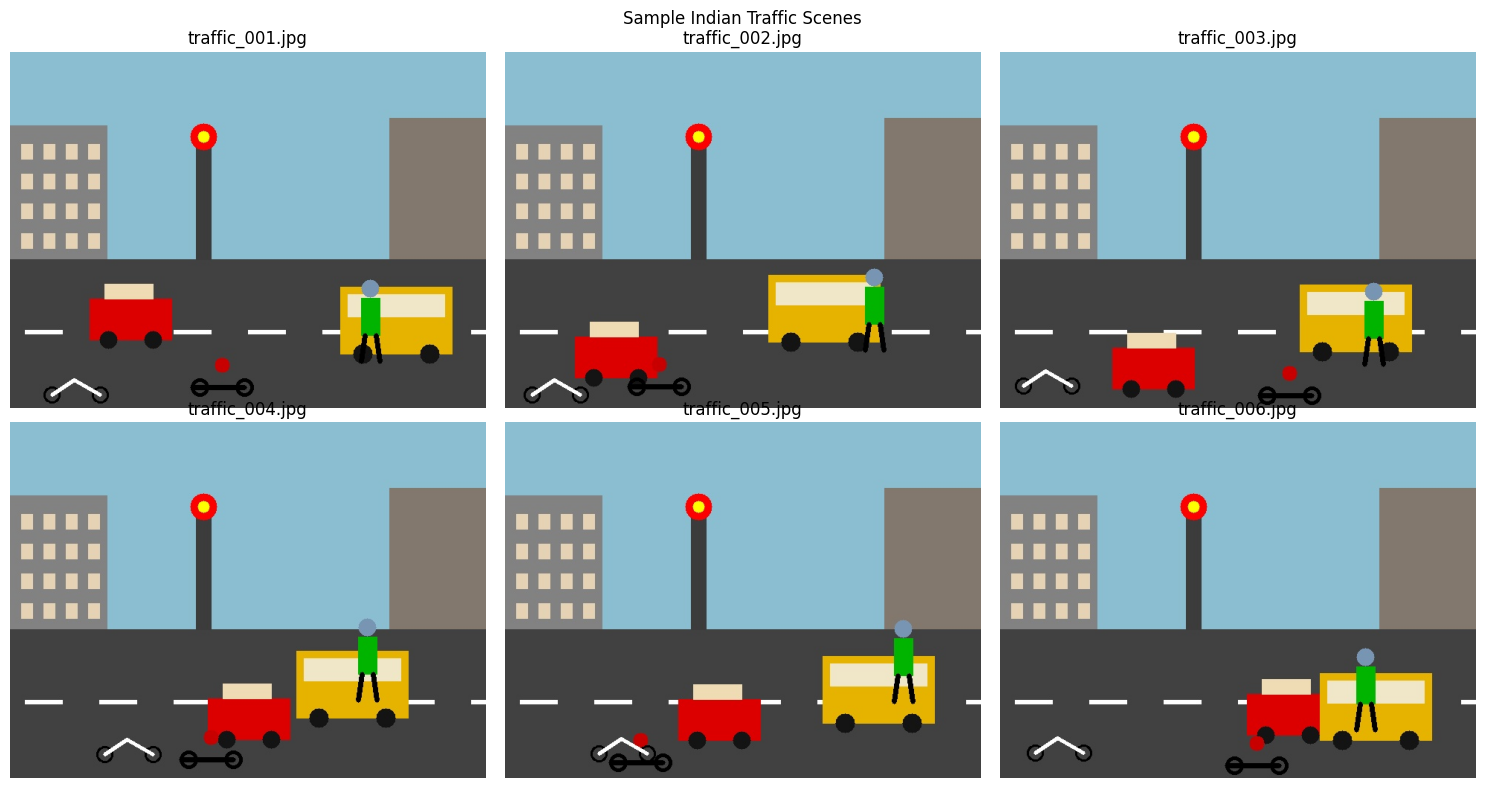

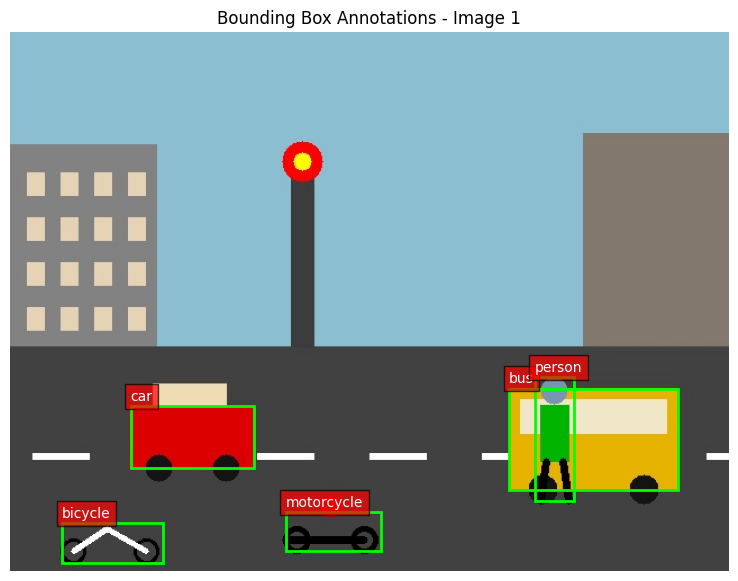

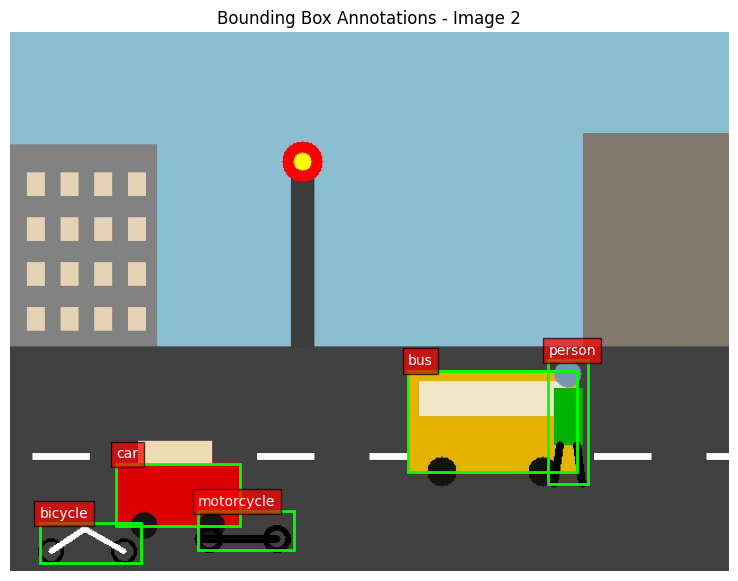

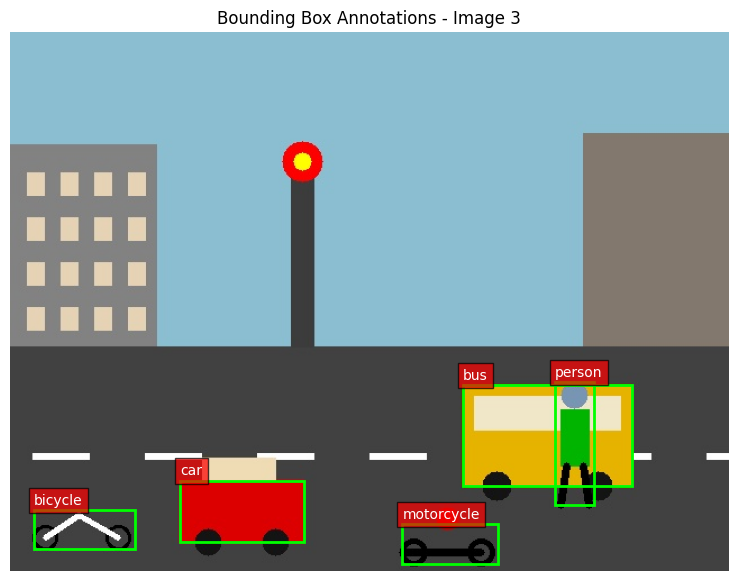


========== IMAGE DIMENSIONS ==========


,file_name,width,height
0,traffic_001.jpg,640,480
1,traffic_002.jpg,640,480
2,traffic_003.jpg,640,480
3,traffic_004.jpg,640,480
4,traffic_005.jpg,640,480
5,traffic_006.jpg,640,480
6,traffic_007.jpg,640,480
7,traffic_008.jpg,640,480
8,traffic_009.jpg,640,480
9,traffic_010.jpg,640,480


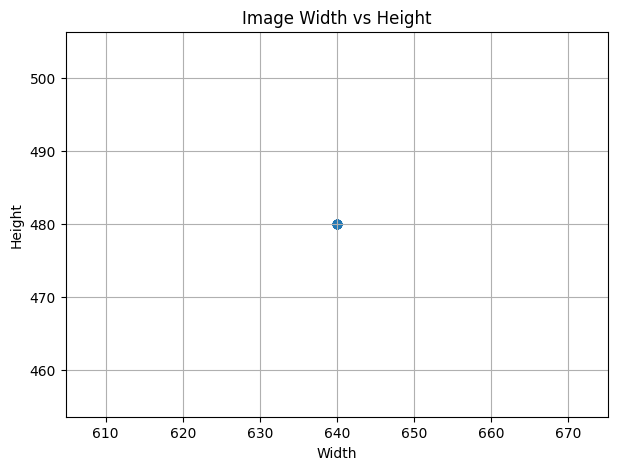

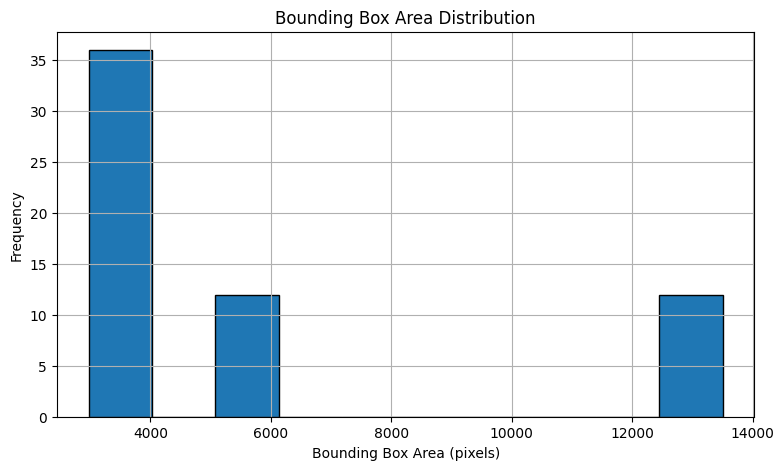

Average Bounding Box Area: 5905.0
Minimum Bounding Box Area: 2975
Maximum Bounding Box Area: 13500

========== ANNOTATION VALIDATION ==========
Valid Annotations: 60
Invalid Annotations: 0

========== IMAGE ANNOTATION SUMMARY ==========


,Image,Annotations
0,traffic_001.jpg,5
1,traffic_002.jpg,5
2,traffic_003.jpg,5
3,traffic_004.jpg,5
4,traffic_005.jpg,5
5,traffic_006.jpg,5
6,traffic_007.jpg,5
7,traffic_008.jpg,5
8,traffic_009.jpg,5
9,traffic_010.jpg,5



Dataset ZIP created successfully!

========== FINAL OBSERVATIONS ==========
1. COCO format stores images, categories and annotations.
2. Six traffic object categories were explored.
3. Class distribution was visualized.
4. Bounding boxes were displayed on sample images.
5. Image dimensions and bounding box areas were analyzed.
6. Annotation validation was performed.
7. Dataset was exported in ZIP format.

ALL OPERATIONS COMPLETED SUCCESSFULLY!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ============================================================
# COCO DATASET EXPLORATION
# Indian Traffic Images, Categories and Bounding-Box Annotation
# ============================================================

import os
import json
import random
import zipfile
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import display

# ------------------------------------------------------------
# 1. CREATE DATASET DIRECTORY
# ------------------------------------------------------------

BASE_DIR = "/content/Indian_Traffic_COCO"
IMAGE_DIR = os.path.join(BASE_DIR, "images")
ANNOTATION_DIR = os.path.join(BASE_DIR, "annotations")

os.makedirs(IMAGE_DIR, exist_ok=True)
os.makedirs(ANNOTATION_DIR, exist_ok=True)

print("Dataset directories created successfully!")

# ------------------------------------------------------------
# 2. DEFINE COCO CATEGORIES
# ------------------------------------------------------------

categories = [
    {"id": 1, "name": "car", "supercategory": "vehicle"},
    {"id": 2, "name": "bus", "supercategory": "vehicle"},
    {"id": 3, "name": "motorcycle", "supercategory": "vehicle"},
    {"id": 4, "name": "person", "supercategory": "human"},
    {"id": 5, "name": "bicycle", "supercategory": "vehicle"},
    {"id": 6, "name": "traffic_light", "supercategory": "object"}
]

category_names = {c["id"]: c["name"] for c in categories}

# ------------------------------------------------------------
# 3. GENERATE SAMPLE INDIAN TRAFFIC SCENES
# ------------------------------------------------------------

random.seed(42)
np.random.seed(42)

images = []
annotations = []

image_count = 12
annotation_id = 1

def create_scene(index):

    img = np.zeros((480, 640, 3), dtype=np.uint8)

    # Sky
    img[:] = (210, 190, 140)

    # Buildings
    cv2.rectangle(img, (0, 100), (130, 280), (130, 130, 130), -1)
    cv2.rectangle(img, (510, 90), (640, 280), (110, 120, 130), -1)

    # Building windows
    for x in range(15, 120, 30):
        for y in range(125, 250, 40):
            cv2.rectangle(img, (x, y), (x+15, y+20),
                          (180, 210, 230), -1)

    # Road
    cv2.rectangle(img, (0, 280), (640, 480), (65, 65, 65), -1)

    # Road divider
    for x in range(20, 640, 100):
        cv2.rectangle(img, (x, 375), (x+50, 380),
                      (255, 255, 255), -1)

    # Indian road-side setting
    cv2.rectangle(img, (250, 120), (270, 280), (60, 60, 60), -1)
    cv2.circle(img, (260, 115), 18, (0, 0, 255), -1)
    cv2.circle(img, (260, 115), 8, (0, 255, 255), -1)

    objects = []

    def add_object(category_id, bbox, draw_function):
        draw_function()
        objects.append({
            "category_id": category_id,
            "bbox": bbox
        })

    # Car
    car_x = random.randint(50, 350)
    car_y = random.randint(330, 400)

    add_object(
        1,
        [car_x, car_y, 110, 55],
        lambda: (
            cv2.rectangle(img, (car_x, car_y),
                          (car_x+110, car_y+55), (0, 0, 220), -1),
            cv2.rectangle(img, (car_x+20, car_y-20),
                          (car_x+85, car_y), (180, 220, 240), -1),
            cv2.circle(img, (car_x+25, car_y+55), 12, (20,20,20), -1),
            cv2.circle(img, (car_x+85, car_y+55), 12, (20,20,20), -1)
        )
    )

    # Bus
    bus_x = random.randint(350, 450)
    bus_y = random.randint(300, 350)

    add_object(
        2,
        [bus_x, bus_y, 150, 90],
        lambda: (
            cv2.rectangle(img, (bus_x, bus_y),
                          (bus_x+150, bus_y+90), (0, 180, 230), -1),
            cv2.rectangle(img, (bus_x+10, bus_y+10),
                          (bus_x+140, bus_y+40), (200,230,240), -1),
            cv2.circle(img, (bus_x+30, bus_y+90), 13, (20,20,20), -1),
            cv2.circle(img, (bus_x+120, bus_y+90), 13, (20,20,20), -1)
        )
    )

    # Motorcycle
    bike_x = random.randint(120, 400)
    bike_y = random.randint(420, 440)

    add_object(
        3,
        [bike_x, bike_y, 85, 35],
        lambda: (
            cv2.line(img, (bike_x, bike_y+25),
                     (bike_x+70, bike_y+25), (0,0,0), 5),
            cv2.circle(img, (bike_x+10, bike_y+25), 10, (0,0,0), 3),
            cv2.circle(img, (bike_x+70, bike_y+25), 10, (0,0,0), 3),
            cv2.circle(img, (bike_x+40, bike_y-5), 10, (0,0,200), -1)
        )
    )

    # Person
    person_x = random.randint(450, 570)
    person_y = random.randint(260, 320)

    add_object(
        4,
        [person_x, person_y, 35, 110],
        lambda: (
            cv2.circle(img, (person_x+17, person_y+12),
                       12, (180, 150, 120), -1),
            cv2.rectangle(img, (person_x+5, person_y+25),
                          (person_x+30, person_y+75), (0, 180, 0), -1),
            cv2.line(img, (person_x+10, person_y+75),
                     (person_x+5, person_y+110), (0,0,0), 5),
            cv2.line(img, (person_x+25, person_y+75),
                     (person_x+30, person_y+110), (0,0,0), 5)
        )
    )

    # Bicycle
    bicycle_x = random.randint(20, 150)
    bicycle_y = random.randint(420, 440)

    add_object(
        5,
        [bicycle_x, bicycle_y, 90, 35],
        lambda: (
            cv2.circle(img, (bicycle_x+10, bicycle_y+25),
                       10, (0,0,0), 2),
            cv2.circle(img, (bicycle_x+75, bicycle_y+25),
                       10, (0,0,0), 2),
            cv2.line(img, (bicycle_x+10, bicycle_y+25),
                     (bicycle_x+40, bicycle_y+5), (255,255,255), 3),
            cv2.line(img, (bicycle_x+40, bicycle_y+5),
                     (bicycle_x+75, bicycle_y+25), (255,255,255), 3)
        )
    )

    return img, objects


# Generate images and annotations

for i in range(image_count):

    img, objects = create_scene(i)

    filename = f"traffic_{i+1:03d}.jpg"
    filepath = os.path.join(IMAGE_DIR, filename)

    cv2.imwrite(filepath, img)

    images.append({
        "id": i+1,
        "file_name": filename,
        "width": 640,
        "height": 480
    })

    for obj in objects:

        x, y, w, h = obj["bbox"]

        annotations.append({
            "id": annotation_id,
            "image_id": i+1,
            "category_id": obj["category_id"],
            "bbox": [x, y, w, h],
            "area": w*h,
            "iscrowd": 0,
            "segmentation": []
        })

        annotation_id += 1

print("Generated images:", len(images))
print("Generated annotations:", len(annotations))

# ------------------------------------------------------------
# 4. CREATE COCO FORMAT JSON FILE
# ------------------------------------------------------------

coco_data = {
    "info": {
        "description": "Indian Traffic COCO Demonstration Dataset",
        "version": "1.0"
    },
    "licenses": [],
    "images": images,
    "annotations": annotations,
    "categories": categories
}

json_path = os.path.join(
    ANNOTATION_DIR, "instances_traffic.json"
)

with open(json_path, "w") as f:
    json.dump(coco_data, f, indent=4)

print("\nCOCO annotation JSON created successfully!")

# ------------------------------------------------------------
# 5. EXPLORE DATASET INFORMATION
# ------------------------------------------------------------

print("\n========== DATASET INFORMATION ==========")

print("Total Images:", len(images))
print("Total Annotations:", len(annotations))
print("Total Categories:", len(categories))

print("\nCategory Names:")

for category in categories:
    print(category["id"], "-", category["name"])

# ------------------------------------------------------------
# 6. CLASS DISTRIBUTION
# ------------------------------------------------------------

class_counts = Counter(
    ann["category_id"] for ann in annotations
)

class_df = pd.DataFrame([
    {
        "Category": category_names[cid],
        "Count": class_counts[cid]
    }
    for cid in category_names
])

print("\n========== CLASS DISTRIBUTION ==========")
display(class_df)

plt.figure(figsize=(10,5))
plt.bar(class_df["Category"], class_df["Count"])
plt.title("COCO Traffic Dataset - Class Distribution")
plt.xlabel("Object Categories")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=30)
plt.grid(axis="y")
plt.show()

# ------------------------------------------------------------
# 7. DISPLAY SAMPLE TRAFFIC IMAGES
# ------------------------------------------------------------

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for i, ax in enumerate(axes.flat):

    image_path = os.path.join(
        IMAGE_DIR, images[i]["file_name"]
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    ax.imshow(image)
    ax.set_title(images[i]["file_name"])
    ax.axis("off")

plt.suptitle("Sample Indian Traffic Scenes")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 8. BOUNDING BOX ANNOTATION VISUALIZATION
# ------------------------------------------------------------

def visualize_annotations(image_id):

    image_info = next(
        img for img in images if img["id"] == image_id
    )

    image_path = os.path.join(
        IMAGE_DIR, image_info["file_name"]
    )

    image = cv2.imread(image_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    image_annotations = [
        ann for ann in annotations
        if ann["image_id"] == image_id
    ]

    plt.figure(figsize=(12, 7))
    plt.imshow(image)

    ax = plt.gca()

    for ann in image_annotations:

        x, y, w, h = ann["bbox"]
        category = category_names[ann["category_id"]]

        rect = plt.Rectangle(
            (x, y), w, h,
            linewidth=2,
            edgecolor="lime",
            facecolor="none"
        )

        ax.add_patch(rect)

        plt.text(
            x, max(0, y-5),
            category,
            color="white",
            fontsize=10,
            bbox=dict(facecolor="red", alpha=0.7)
        )

    plt.title(f"Bounding Box Annotations - Image {image_id}")
    plt.axis("off")
    plt.show()


visualize_annotations(1)
visualize_annotations(2)
visualize_annotations(3)

# ------------------------------------------------------------
# 9. IMAGE DIMENSION ANALYSIS
# ------------------------------------------------------------

dimension_df = pd.DataFrame(images)

print("\n========== IMAGE DIMENSIONS ==========")
display(dimension_df[["file_name", "width", "height"]])

plt.figure(figsize=(7,5))

plt.scatter(
    dimension_df["width"],
    dimension_df["height"]
)

plt.title("Image Width vs Height")
plt.xlabel("Width")
plt.ylabel("Height")
plt.grid()
plt.show()

# ------------------------------------------------------------
# 10. BOUNDING BOX AREA ANALYSIS
# ------------------------------------------------------------

bbox_areas = [ann["area"] for ann in annotations]

plt.figure(figsize=(9,5))
plt.hist(bbox_areas, bins=10, edgecolor="black")
plt.title("Bounding Box Area Distribution")
plt.xlabel("Bounding Box Area (pixels)")
plt.ylabel("Frequency")
plt.grid()
plt.show()

print("Average Bounding Box Area:",
      np.mean(bbox_areas))

print("Minimum Bounding Box Area:",
      np.min(bbox_areas))

print("Maximum Bounding Box Area:",
      np.max(bbox_areas))

# ------------------------------------------------------------
# 11. ANNOTATION VALIDATION
# ------------------------------------------------------------

print("\n========== ANNOTATION VALIDATION ==========")

valid_count = 0
invalid_count = 0

for ann in annotations:

    x, y, w, h = ann["bbox"]

    valid = (
        w > 0 and h > 0 and
        x >= 0 and y >= 0 and
        x+w <= 640 and y+h <= 480 and
        ann["category_id"] in category_names
    )

    if valid:
        valid_count += 1
    else:
        invalid_count += 1

print("Valid Annotations:", valid_count)
print("Invalid Annotations:", invalid_count)

# ------------------------------------------------------------
# 12. IMAGE-WISE ANNOTATION SUMMARY
# ------------------------------------------------------------

image_summary = []

for img in images:

    count = sum(
        1 for ann in annotations
        if ann["image_id"] == img["id"]
    )

    image_summary.append({
        "Image": img["file_name"],
        "Annotations": count
    })

summary_df = pd.DataFrame(image_summary)

print("\n========== IMAGE ANNOTATION SUMMARY ==========")
display(summary_df)

# ------------------------------------------------------------
# 13. SAVE COMPLETE DATASET AS ZIP
# ------------------------------------------------------------

zip_path = "/content/Indian_Traffic_COCO.zip"

with zipfile.ZipFile(zip_path, "w",
                     zipfile.ZIP_DEFLATED) as zipf:

    for root, dirs, files in os.walk(BASE_DIR):

        for file in files:

            full_path = os.path.join(root, file)

            arcname = os.path.relpath(
                full_path, BASE_DIR
            )

            zipf.write(full_path, arcname)

print("\nDataset ZIP created successfully!")

# ------------------------------------------------------------
# 14. FINAL OBSERVATIONS
# ------------------------------------------------------------

print("\n========== FINAL OBSERVATIONS ==========")

print("1. COCO format stores images, categories and annotations.")
print("2. Six traffic object categories were explored.")
print("3. Class distribution was visualized.")
print("4. Bounding boxes were displayed on sample images.")
print("5. Image dimensions and bounding box areas were analyzed.")
print("6. Annotation validation was performed.")
print("7. Dataset was exported in ZIP format.")

print("\nALL OPERATIONS COMPLETED SUCCESSFULLY!")

# ------------------------------------------------------------
# 15. DOWNLOAD DATASET
# ------------------------------------------------------------

from google.colab import files

files.download(zip_path)
